# 03. Tone mapping, denoising and sharpening

After white balance and demosaicing the image is still linear, noisy and soft. Three jobs remain: squeeze the scene's brightness range into something a display can show (L4 s13-18), remove noise without erasing edges (L5 s5-10), and put crispness back (L5 s12-16). Each step has a cheap global version and a better edge-aware one, and each can be overdone. Theory: `docs/04_tone_mapping.md`, `docs/05_denoising.md`, `docs/06_sharpening.md`.

In [1]:
%matplotlib inline
# JPEG keeps the executed notebooks small (plots are photographs).
%config InlineBackend.figure_format = 'jpeg'
import sys, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 80
# Make `import isp` work whether Jupyter was started in the project root or in notebooks/.
_cwd = pathlib.Path.cwd().resolve()
ROOT = _cwd.parent if _cwd.name == 'notebooks' else _cwd
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import isp
from isp import utils, scenes
srgb = utils.linear_to_srgb      # linear light -> display values for imshow


def show_row(images, titles, figsize=(12, 4), cmap=None, vmin=None, vmax=None):
    # one row of image panels, axes off
    fig, axs = plt.subplots(1, len(images), figsize=figsize)
    for ax, im, t in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(np.clip(im, 0, 1) if (vmin is None and im.ndim == 3) else im,
                  cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(t, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

from isp import tonemap, denoise, sharpen
import ipywidgets as W

hc = scenes.high_contrast(256)                       # linear; the left side is ~50x darker than the right
clean = srgb(scenes.load('astronaut', 256))          # display-referred clean photo for the denoise / sharpen parts
noisy = np.clip(clean + utils.rng(0).normal(0, 0.06, clean.shape), 0, 1).astype(np.float32)
print('high-contrast scene: mean linear value left third %.3f, right third %.3f' % (hc[:, :85].mean(), hc[:, 171:].mean()))
print('noisy photo PSNR vs clean: %.1f dB' % utils.psnr(noisy, clean))

high-contrast scene: mean linear value left third 0.006, right third 0.269
noisy photo PSNR vs clean: 24.9 dB


## Gamma and the sRGB curve (L4 s14)

Linear values put almost everything of a dim scene in the first few display levels. A power curve $\text{out}=\text{in}^{g}$ with $g<1$ lifts the shadows; sRGB is close to $g=1/2.2$ with a straight start near black. It is one fixed curve for the whole picture.

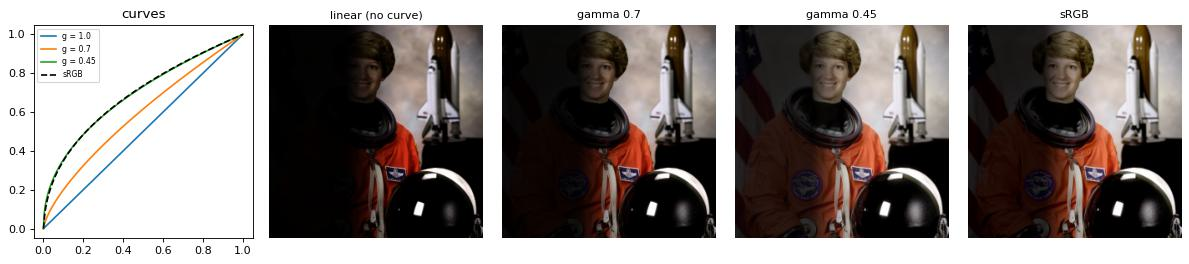

In [2]:
def gamma_demo(img, gammas=(1.0, 0.7, 0.45), plot=True):
    x = np.linspace(0, 1, 256)
    outs = [tonemap.tonemap(img, 'linear')] + [tonemap.tonemap(img, 'gamma', g=g) for g in gammas[1:]] + [tonemap.tonemap(img, 'srgb')]
    if plot:
        fig, axs = plt.subplots(1, 5, figsize=(15, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 1]))
        for g in gammas:
            axs[0].plot(x, x ** g, label=f'g = {g}')
        axs[0].plot(x, utils.linear_to_srgb(x), 'k--', label='sRGB'); axs[0].legend(fontsize=7); axs[0].set_title('curves')
        for ax, o, t in zip(axs[1:], outs, ['linear (no curve)'] + [f'gamma {g}' for g in gammas[1:]] + ['sRGB']):
            ax.imshow(o); ax.axis('off'); ax.set_title(t, fontsize=10)
        plt.tight_layout(); plt.show()
    return outs

_ = gamma_demo(hc)

Without a curve the dark half is nearly black. Gamma and sRGB open it up, and they do it everywhere, including the bright window, which begins to wash out. A curve that depends only on the input value cannot treat the two regions differently.

## Histogram equalisation (L4 s15)

Equalisation picks the curve from the picture itself: the CDF of the luminance histogram, so every output level is used about equally. CLAHE does it per tile with a clip limit so noise in flat areas is not blown up.

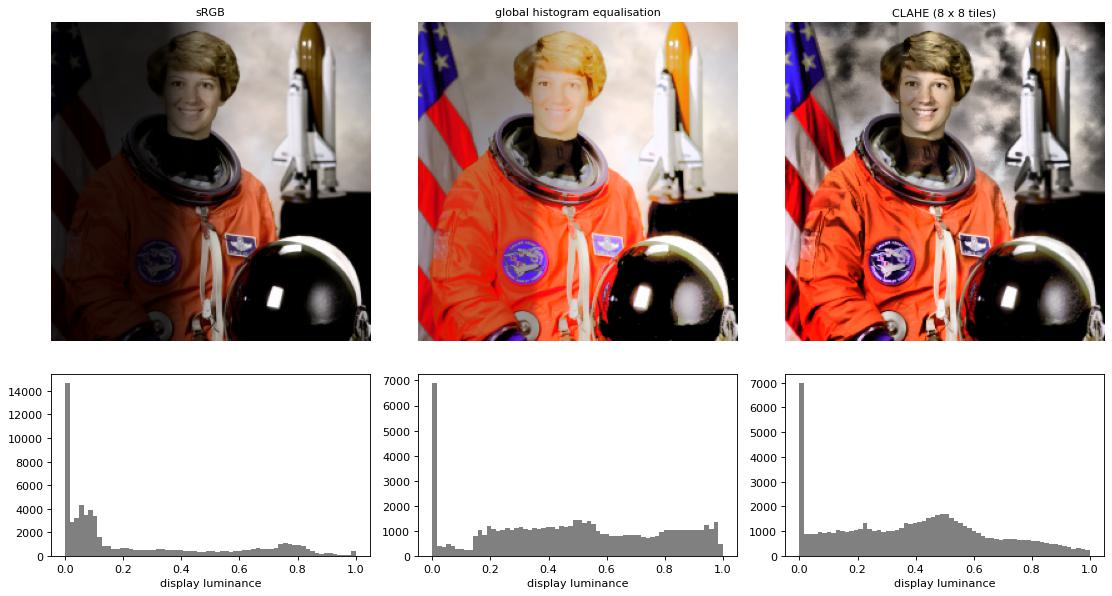

In [3]:
def hist_demo(img, plot=True):
    outs = {'sRGB': tonemap.tonemap(img, 'srgb'), 'global histogram equalisation': tonemap.tonemap(img, 'hist'),
            'CLAHE (8 x 8 tiles)': tonemap.tonemap(img, 'clahe')}
    if plot:
        fig, axs = plt.subplots(2, 3, figsize=(14, 8), gridspec_kw=dict(height_ratios=[3, 1.3]))
        for j, (name, o) in enumerate(outs.items()):
            axs[0, j].imshow(o); axs[0, j].axis('off'); axs[0, j].set_title(name, fontsize=10)
            axs[1, j].hist(utils.luminance(o).ravel(), bins=64, range=(0, 1), color='gray'); axs[1, j].set_xlabel('display luminance')
        plt.tight_layout(); plt.show()
    return outs

_ = hist_demo(hc)

The sRGB histogram piles up at the dark end; equalisation spreads it flat and pulls detail out of the dark half, at the price of an unnatural, contrasty look. Both are still global (CLAHE less so). The step that follows is the one that treats regions differently.

## Global against local: dodging and burning (L4 s16-18)

Local tone mapping splits log-luminance into a smooth *base* (the large brightness differences between regions) and *detail*. It compresses the base towards its brightest value and keeps the detail, which is what a darkroom printer does with dodge and burn. `strength` is how much of the base contrast is removed.

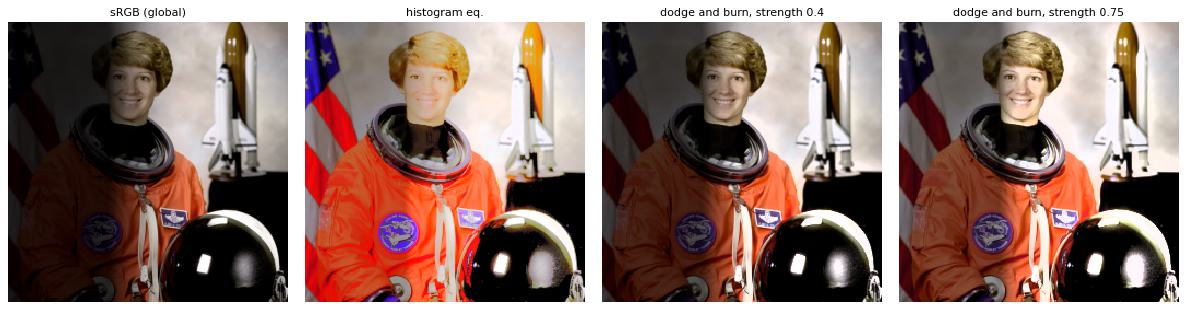

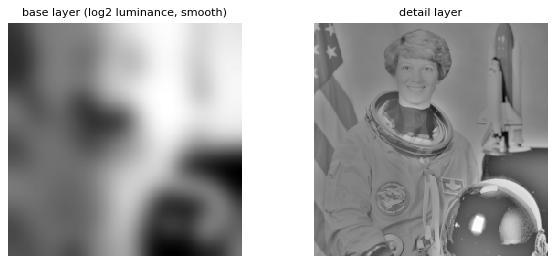

                                  dark left bright right    ratio
sRGB (global)                         0.054      0.411      7.6
histogram eq.                         0.340      0.566      1.7
dodge and burn, strength 0.4          0.129      0.491      3.8
dodge and burn, strength 0.75         0.245      0.552      2.3


In [4]:
def tone_compare(img, strengths=(0.4, 0.75), plot=True):
    outs = {'sRGB (global)': tonemap.tonemap(img, 'srgb'), 'histogram eq.': tonemap.tonemap(img, 'hist')}
    for s in strengths:
        outs[f'dodge and burn, strength {s}'] = tonemap.tonemap(img, 'local', strength=s)
    stats = {k: (utils.luminance(o)[:, :85].mean(), utils.luminance(o)[:, 171:].mean()) for k, o in outs.items()}
    if plot:
        show_row(list(outs.values()), list(outs), figsize=(15, 3.8))
        base, detail = tonemap.decompose(img)
        show_row([base, detail], ['base layer (log2 luminance, smooth)', 'detail layer'], figsize=(8, 3.4), cmap='gray', vmin=None, vmax=None)
    return stats

stats = tone_compare(hc)
print('{:32s} {:>10s} {:>10s} {:>8s}'.format('', 'dark left', 'bright right', 'ratio'))
for k, (a, b) in stats.items():
    print('{:32s} {:10.3f} {:10.3f} {:8.1f}'.format(k, a, b, b / a))

The ratio of the two sides in display luminance shrinks as the local operator gets stronger, while the detail inside each region survives (look at the face and suit on the left). The cost is an artificial, flat look at high strength; the base layer's blur radius sets the halos around bright objects.

## Gaussian against bilateral denoising (L5 s5-9)

A Gaussian averages neighbours by distance only, so it blurs across edges. The bilateral filter multiplies that weight by a second one that depends on how different the intensity is:
$$w(i,j,k,l)=\exp\!\Big(-\tfrac{(i-k)^2+(j-l)^2}{2\sigma_d^2}-\tfrac{\|I(i,j)-I(k,l)\|^2}{2\sigma_r^2}\Big),\qquad I_D(i,j)=\frac{\sum I(k,l)\,w}{\sum w}.$$
The photo below has Gaussian noise added in the display domain; the numbers are PSNR and SSIM against the clean picture.

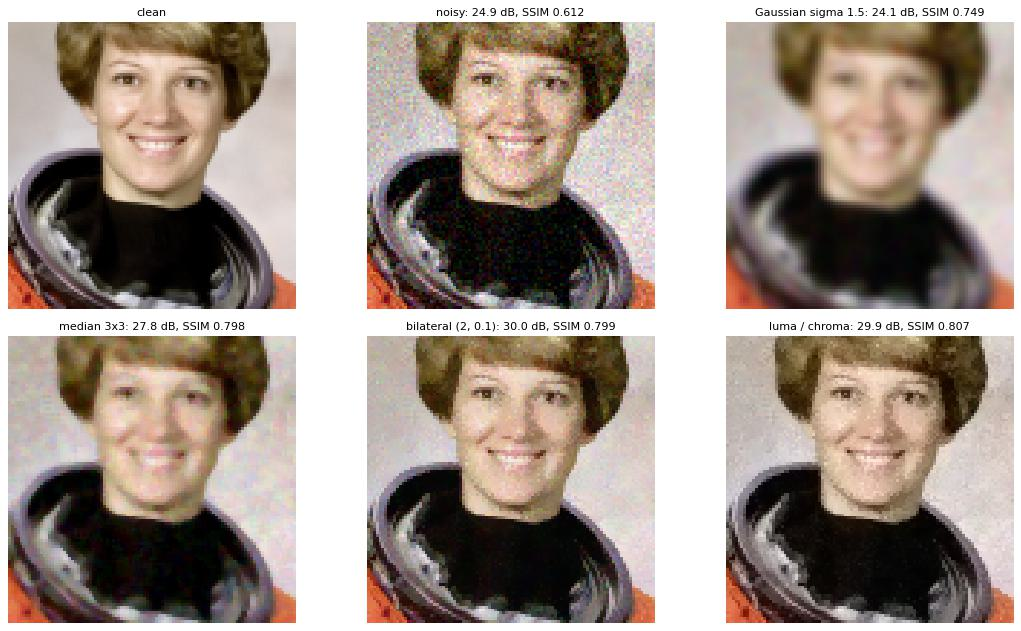

In [5]:
def denoise_compare(noisy, clean, crop=(30, 130, 60, 160), plot=True):
    outs = {'noisy': noisy,
            'Gaussian sigma 1.5': denoise.gaussian(noisy, 1.5),
            'median 3x3': denoise.median(noisy, 3),
            'bilateral (2, 0.1)': denoise.bilateral(noisy, sigma_d=2.0, sigma_r=0.1),
            'luma / chroma': denoise.luma_chroma(noisy)}
    outs = {k: np.clip(v, 0, 1) for k, v in outs.items()}
    m = {k: (utils.psnr(clean, v), utils.ssim(clean, v)) for k, v in outs.items()}
    if plot:
        sl = (slice(crop[0], crop[1]), slice(crop[2], crop[3]))
        fig, axs = plt.subplots(2, 3, figsize=(14, 8))
        for ax, (k, v) in zip(axs.ravel(), [('clean', clean)] + list(outs.items())):
            ax.imshow(v[sl], interpolation='nearest'); ax.axis('off')
            ax.set_title(k if k == 'clean' else f'{k}: {m[k][0]:.1f} dB, SSIM {m[k][1]:.3f}', fontsize=10)
        plt.tight_layout(); plt.show()
    return m

m_dn = denoise_compare(noisy, clean)

The Gaussian removes noise but smears the eyes and the collar ring; the bilateral keeps those edges and still smooths the flat skin, which shows in PSNR and SSIM. The median is better than the Gaussian but still rounds off fine features.

## What the bilateral filter does at an edge (L5 s6-9)

The weight window around one pixel is the thing to look at. Next to a step edge, the Gaussian window straddles it and averages the two sides; the bilateral one fades out the pixels across the edge, because their value differs by more than $\sigma_r$.

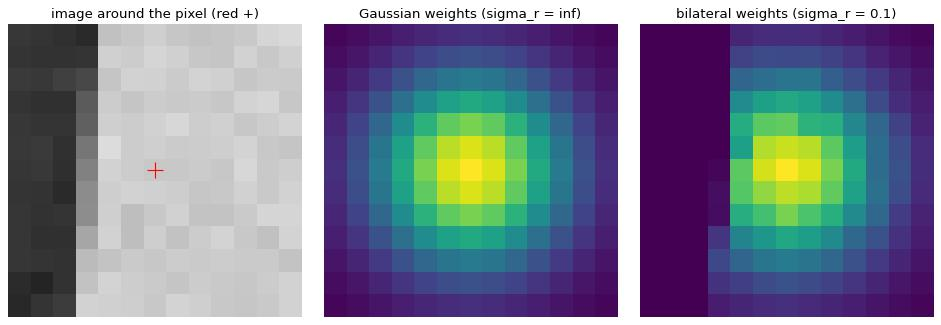

share of the weight that falls on the dark side of the edge: Gaussian 14 %, bilateral 0.0 %


In [6]:
def weight_windows(sigma_d=3.0, sigma_r=0.1, offset=3, noise=0.02, plot=True):
    img = scenes.step_edge(64)[..., 0]
    img = (img + utils.rng(1).normal(0, noise, img.shape)).astype(np.float32)
    c = (32, 32 + offset)                                   # a pixel `offset` px to the bright side of the edge
    gauss = denoise.bilateral_weights(img, c, sigma_d, np.inf)
    bil = denoise.bilateral_weights(img, c, sigma_d, sigma_r)
    r = gauss.shape[0] // 2
    if plot:
        fig, axs = plt.subplots(1, 3, figsize=(12, 4))
        axs[0].imshow(img[c[0] - r:c[0] + r + 1, c[1] - r:c[1] + r + 1], cmap='gray', vmin=0, vmax=1)
        axs[0].plot(r, r, 'r+', ms=14); axs[0].set_title('image around the pixel (red +)')
        axs[1].imshow(gauss, vmin=0, vmax=1); axs[1].set_title('Gaussian weights (sigma_r = inf)')
        axs[2].imshow(bil, vmin=0, vmax=1); axs[2].set_title(f'bilateral weights (sigma_r = {sigma_r})')
        for ax in axs: ax.axis('off')
        plt.tight_layout(); plt.show()
    dark = img[c[0] - r:c[0] + r + 1, c[1] - r:c[1] + r + 1] < 0.5          # window pixels on the dark side of the edge
    return float(gauss[dark].sum() / gauss.sum()), float(bil[dark].sum() / bil.sum())

wg, wbil = weight_windows()
print(f'share of the weight that falls on the dark side of the edge: Gaussian {100 * wg:.0f} %, bilateral {100 * wbil:.1f} %')

The bilateral window keeps only the bright side, so averaging with it cannot pull the dark side's values in. The tuning rule follows from this: $\sigma_r$ should be a bit above the noise level (so noise differences count as "similar") and below the contrast of the edges you want to keep.

## Luma and chroma denoising (L5 s10)

Colour noise can be smoothed harder than brightness noise (notebook 02, luma against chroma). `luma_chroma` filters Y gently and Cb, Cr with a big window.

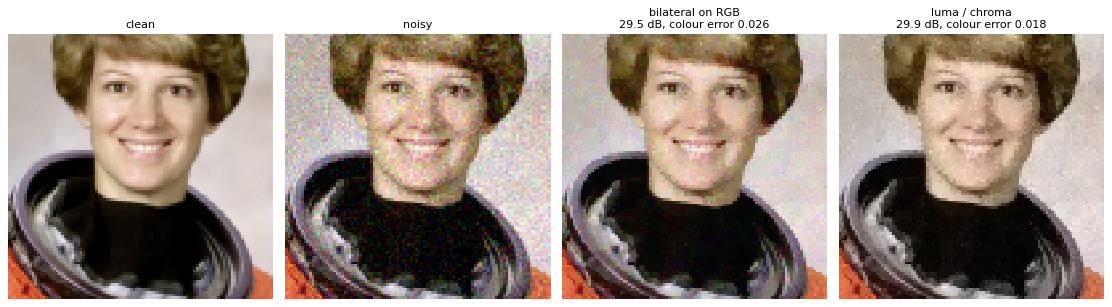

In [7]:
def chroma_demo(noisy, clean, crop=(30, 130, 60, 160), plot=True):
    rgb_f = np.clip(denoise.bilateral(noisy, sigma_d=1.5, sigma_r=0.1), 0, 1)
    lc = np.clip(denoise.luma_chroma(noisy), 0, 1)
    from isp import demosaic
    m = {k: (utils.psnr(clean, v), demosaic.false_color(v, clean)) for k, v in {'noisy': noisy, 'bilateral on RGB': rgb_f, 'luma / chroma': lc}.items()}
    if plot:
        sl = (slice(crop[0], crop[1]), slice(crop[2], crop[3]))
        show_row([clean[sl], noisy[sl], rgb_f[sl], lc[sl]], ['clean', 'noisy'] + [f'{k}\n{m[k][0]:.1f} dB, colour error {m[k][1]:.3f}' for k in list(m)[1:]], figsize=(14, 3.8))
    return m

_ = chroma_demo(noisy, clean)

The luma/chroma version has a clearly lower colour error (the number under each panel) at a similar PSNR, because chroma is smoothed over a large window while luma is filtered gently. What is left is mostly luminance grain, which the eye finds less objectionable than colour speckle.

## Choosing $(\sigma_d, \sigma_r)$

A small sweep on a 128 x 128 version of the noisy photo: PSNR for each pair, and three pictures from the grid. Too small a $\sigma_r$ leaves the noise, too large turns the filter into a Gaussian.

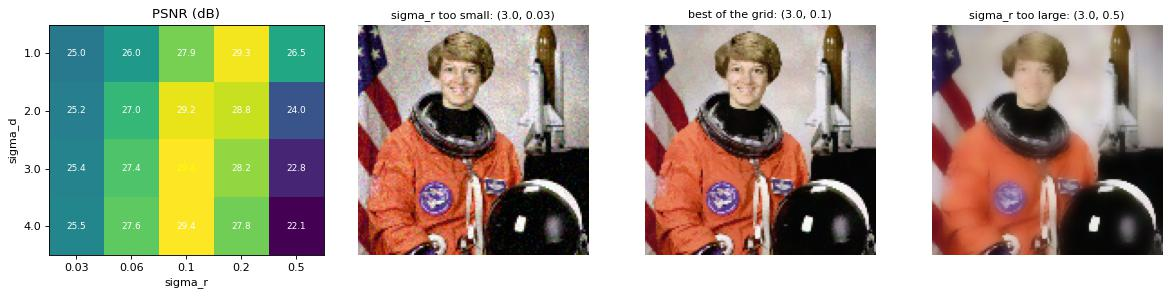

best (sigma_d, sigma_r): (3.0, 0.1)   noise std was 0.06


In [8]:
def sweep_bilateral(noisy, clean, sigma_ds=(1.0, 2.0, 3.0, 4.0), sigma_rs=(0.03, 0.06, 0.1, 0.2, 0.5), plot=True):
    grid = np.array([[utils.psnr(clean, np.clip(denoise.bilateral(noisy, d, r), 0, 1)) for r in sigma_rs] for d in sigma_ds])
    i, j = np.unravel_index(grid.argmax(), grid.shape)
    if plot:
        fig, axs = plt.subplots(1, 4, figsize=(15, 3.8))
        axs[0].imshow(grid, cmap='viridis', aspect='auto')
        axs[0].set_xticks(range(len(sigma_rs)), sigma_rs); axs[0].set_yticks(range(len(sigma_ds)), sigma_ds)
        axs[0].set_xlabel('sigma_r'); axs[0].set_ylabel('sigma_d'); axs[0].set_title('PSNR (dB)')
        for a in range(grid.shape[0]):
            for b in range(grid.shape[1]):
                axs[0].text(b, a, f'{grid[a, b]:.1f}', ha='center', va='center', color='w' if (a, b) != (i, j) else 'yellow', fontsize=8)
        picks = [(sigma_ds[i], sigma_rs[0]), (sigma_ds[i], sigma_rs[j]), (sigma_ds[i], sigma_rs[-1])]
        for ax, (d, r), t in zip(axs[1:], picks, ['sigma_r too small', 'best of the grid', 'sigma_r too large']):
            ax.imshow(np.clip(denoise.bilateral(noisy, d, r), 0, 1)); ax.axis('off')
            ax.set_title(f'{t}: ({d}, {r})', fontsize=10)
        plt.tight_layout(); plt.show()
    return grid, (sigma_ds[i], sigma_rs[j])

small_clean = clean[::2, ::2]
small_noisy = np.clip(small_clean + utils.rng(2).normal(0, 0.06, small_clean.shape), 0, 1).astype(np.float32)
grid, best = sweep_bilateral(small_noisy, small_clean)
print('best (sigma_d, sigma_r):', best, '  noise std was 0.06')

The best $\sigma_r$ sits somewhat above the noise standard deviation, as the rule says, and larger $\sigma_d$ helps while noise dominates. At the large end of $\sigma_r$ the filter degrades towards a Gaussian blur; at the small end it does almost nothing.

## Laplacian sharpening (L5 s12-14)

Sharpening adds a high-pass copy of the image back to itself, $S = x + \lambda F(x)$. With the 4-neighbour Laplacian as $F$, the whole operation is a single 3x3 kernel whose taps sum to 1 (brightness is preserved). $\lambda=1$ and $\lambda=2$ give the two Photoshop kernels shown on the slides.

sharpening_kernel(lam=1):
 [[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]
sharpening_kernel(lam=2):
 [[ 0. -2.  0.]
 [-2.  9. -2.]
 [ 0. -2.  0.]]


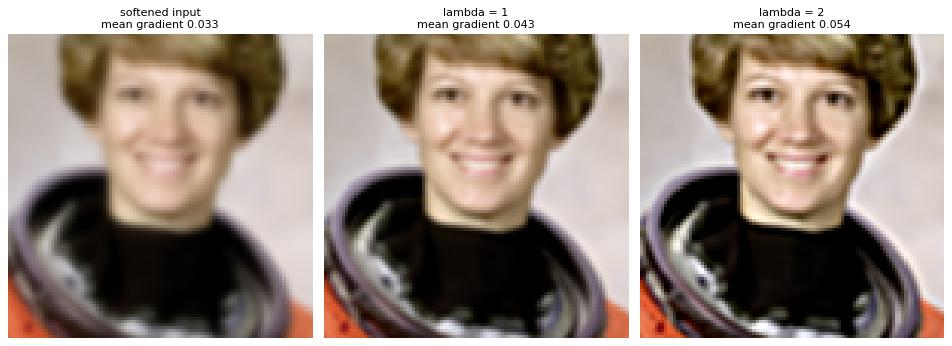

In [9]:
def laplacian_demo(img, lams=(1.0, 2.0), blur=1.2, crop=(30, 130, 60, 160), plot=True):
    soft = np.clip(denoise.gaussian(img, blur), 0, 1)
    outs = {'softened input': soft}
    for lam in lams:
        outs[f'lambda = {lam:g}'] = sharpen.sharpen(soft, 'laplacian', lam=lam)
    grads = {k: sharpen.mean_gradient(v) for k, v in outs.items()}
    if plot:
        sl = (slice(crop[0], crop[1]), slice(crop[2], crop[3]))
        show_row([v[sl] for v in outs.values()], [f'{k}\nmean gradient {grads[k]:.3f}' for k in outs], figsize=(12, 4.4))
    return grads

for lam in (1, 2):
    print(f'sharpening_kernel(lam={lam}):\n', sharpen.sharpening_kernel(lam))
_ = laplacian_demo(clean)

The kernel centre is $1+4\lambda$ and the four neighbours are $-\lambda$. The mean gradient (a crude sharpness measure) goes up with $\lambda$; the picture gains crispness first and then starts to look harsh, with bright and dark lines along edges.

## Unsharp masking (L5 s15) and why it works

The classic version uses $F = x - G_\sigma * x$: subtract a blurred copy. $\sigma$ chooses which detail size is boosted, whereas the Laplacian always acts at pixel scale. In frequency terms the sharpening filter has gain 1 at zero frequency and more than 1 at high frequencies, which is also where noise lives.

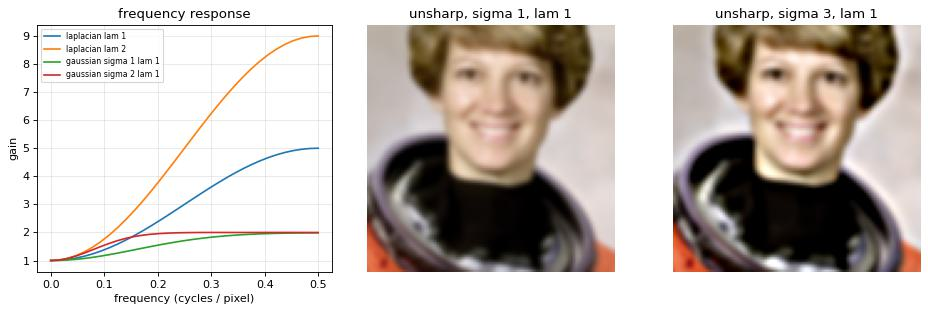

{'laplacian lam 1': 5.0, 'laplacian lam 2': 9.0, 'gaussian sigma 1 lam 1': 1.99, 'gaussian sigma 2 lam 1': 2.0} <- gain at the Nyquist frequency


In [10]:
def response_demo(plot=True):
    n = 64
    cases = [('laplacian lam 1', dict(lam=1.0, kind='laplacian')), ('laplacian lam 2', dict(lam=2.0, kind='laplacian')),
             ('gaussian sigma 1 lam 1', dict(lam=1.0, kind='gaussian', sigma=1.0)), ('gaussian sigma 2 lam 1', dict(lam=1.0, kind='gaussian', sigma=2.0))]
    resp = {k: sharpen.unsharp_response(n=n, **kw)[0, :n // 2 + 1] for k, kw in cases}
    if plot:
        f = np.linspace(0, 0.5, n // 2 + 1)
        fig, axs = plt.subplots(1, 3, figsize=(12, 4))
        for k, r in resp.items():
            axs[0].plot(f, r, label=k)
        axs[0].set_xlabel('frequency (cycles / pixel)'); axs[0].set_ylabel('gain'); axs[0].legend(fontsize=7); axs[0].set_title('frequency response'); axs[0].grid(alpha=.3)
        soft = np.clip(denoise.gaussian(clean, 1.2), 0, 1)
        sl = (slice(30, 130), slice(60, 160))
        axs[1].imshow(sharpen.sharpen(soft, 'unsharp', lam=1.0, sigma=1.0)[sl]); axs[1].set_title('unsharp, sigma 1, lam 1'); axs[1].axis('off')
        axs[2].imshow(sharpen.sharpen(soft, 'unsharp', lam=1.0, sigma=3.0)[sl]); axs[2].set_title('unsharp, sigma 3, lam 1'); axs[2].axis('off')
        plt.tight_layout(); plt.show()
    return {k: float(r[-1]) for k, r in resp.items()}

print({k: round(v, 2) for k, v in response_demo().items()}, '<- gain at the Nyquist frequency')

All the filters leave flat areas (frequency 0) untouched and boost high frequencies; the Laplacian boosts the most at Nyquist, the Gaussian version with a larger $\sigma$ lifts a wider band, so it looks like a local contrast boost rather than pixel-level crispness.

## Overshoot and noise amplification

Every sharpener has two side effects. Around a step edge it overshoots both plateaus (the halo), and since it amplifies high frequencies it amplifies noise: for white noise the standard deviation is multiplied by $\sqrt{\sum \text{taps}^2}$ of the kernel.

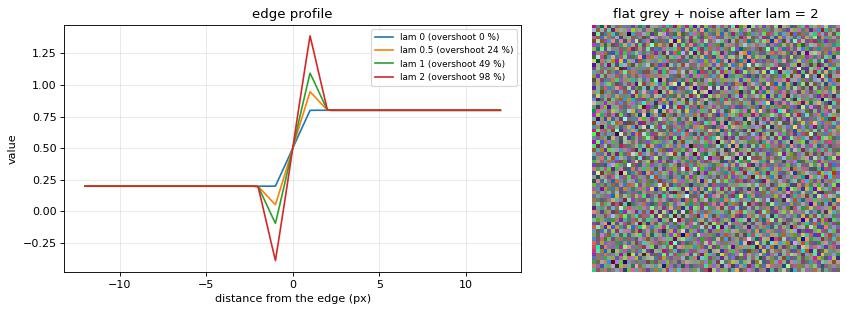

   lam    overshoot   noise std gain  sqrt(sum k^2)
   0.0         0.0%             1.00           1.00
   0.5        24.3%             3.17           3.16
   1.0        48.9%             5.40           5.39
   2.0        97.9%             9.88           9.85


In [11]:
def side_effects(lams=(0.0, 0.5, 1.0, 2.0), noise=0.02, plot=True):
    edge = scenes.step_edge(128)
    flat = np.full((128, 128, 3), 0.5, np.float32)
    flat_n = (flat + utils.rng(3).normal(0, noise, flat.shape)).astype(np.float32)
    rows = []
    fig, ax = (plt.subplots(1, 2, figsize=(12, 4)) if plot else (None, [None, None]))
    for lam in lams:
        d, prof = sharpen.edge_profile(sharpen.sharpen(edge, 'laplacian', lam=lam, clip=False))
        os_ = sharpen.overshoot(prof)
        out = sharpen.sharpen(flat_n, 'laplacian', lam=lam, clip=False)
        gain = out.std() / flat_n.std()
        rows.append((lam, os_, gain, sharpen.noise_gain(sharpen.sharpening_kernel(lam))))
        if plot:
            ax[0].plot(d, prof, label=f'lam {lam:g} (overshoot {100 * os_:.0f} %)')
    if plot:
        ax[0].set_xlabel('distance from the edge (px)'); ax[0].set_ylabel('value'); ax[0].legend(fontsize=8); ax[0].set_title('edge profile'); ax[0].grid(alpha=.3)
        ax[1].imshow(np.clip(out[:64, :64] * 1.0, 0, 1)); ax[1].set_title(f'flat grey + noise after lam = {lams[-1]:g}'); ax[1].axis('off')
        plt.tight_layout(); plt.show()
    return rows

rows = side_effects()
print('{:>6s} {:>12s} {:>16s} {:>14s}'.format('lam', 'overshoot', 'noise std gain', 'sqrt(sum k^2)'))
for lam, o, g, th in rows:
    print('{:6.1f} {:11.1f}% {:16.2f} {:14.2f}'.format(lam, 100 * o, g, th))

The overshoot grows with $\lambda$ and the measured noise gain matches the kernel formula. A sharpener that is strong enough to look good on a clean picture makes the noise several times larger, which leads to the order of operations below.

## Denoise first, then sharpen

If you sharpen a noisy image you amplify the noise and the denoiser then has to deal with stronger, more structured noise; if you denoise first, the sharpener works on a cleaner signal. The test is the same pair of operations in both orders.

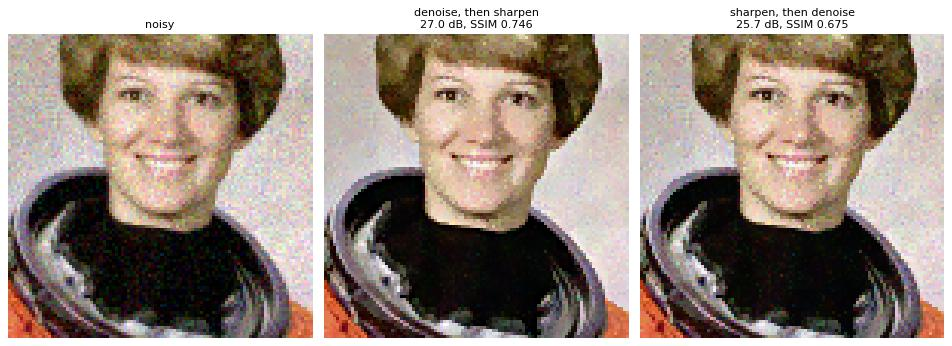

In [12]:
def order_demo(noisy, clean, lam=0.4, crop=(30, 130, 60, 160), plot=True):
    dn = lambda x: np.clip(denoise.bilateral(x, 2.0, 0.1), 0, 1)
    sh = lambda x: sharpen.sharpen(x, 'unsharp', lam=lam, sigma=1.5)
    outs = {'denoise, then sharpen': sh(dn(noisy)), 'sharpen, then denoise': dn(sh(noisy))}
    m = {k: (utils.psnr(clean, v), utils.ssim(clean, v)) for k, v in outs.items()}
    if plot:
        sl = (slice(crop[0], crop[1]), slice(crop[2], crop[3]))
        show_row([noisy[sl]] + [v[sl] for v in outs.values()], ['noisy'] + [f'{k}\n{m[k][0]:.1f} dB, SSIM {m[k][1]:.3f}' for k in outs], figsize=(12, 4.4))
    return m

_ = order_demo(noisy, clean)

Denoising first gives the cleaner result in both metrics. The reverse order sharpens noise into small blobs that a bilateral filter reads as real texture and therefore keeps. The default camera of notebook 04 follows this order, and it also sharpens after tone mapping, on display data.

## Interactive: denoise and sharpen

Change the noise level and the filter settings and watch the PSNR. The crop is the same region as above.

In [13]:
_clean_i = clean[::1, ::1]

def ds_view(noise=0.06, sigma_d=2.0, sigma_r=0.1, lam=0.5, usigma=1.5):
    nz = np.clip(_clean_i + utils.rng(5).normal(0, noise, _clean_i.shape), 0, 1).astype(np.float32)
    den = np.clip(denoise.bilateral(nz, sigma_d, sigma_r), 0, 1)
    out = sharpen.sharpen(den, 'unsharp', lam=lam, sigma=usigma) if lam > 0 else den
    sl = (slice(30, 130), slice(60, 160))
    show_row([nz[sl], den[sl], out[sl]],
             [f'noisy {utils.psnr(_clean_i, nz):.1f} dB', f'bilateral({sigma_d}, {sigma_r}): {utils.psnr(_clean_i, den):.1f} dB', f'+ unsharp({lam}, {usigma}): {utils.psnr(_clean_i, out):.1f} dB'],
             figsize=(12, 4.4))

W.interact(ds_view, noise=W.FloatSlider(min=0.0, max=0.15, step=0.01, value=0.06), sigma_d=W.FloatSlider(min=0.5, max=4, step=0.5, value=2.0),
           sigma_r=W.FloatSlider(min=0.02, max=0.5, step=0.02, value=0.1), lam=W.FloatSlider(min=0, max=3, step=0.25, value=0.5),
           usigma=W.FloatSlider(min=0.5, max=4, step=0.5, value=1.5));

interactive(children=(FloatSlider(value=0.06, description='noise', max=0.15, step=0.01), FloatSlider(value=2.0…

## Try it

1. In `tone_compare`, use `scenes.high_contrast(256, 'coffee')` and a stronger `strength`. Where do halos first appear? Try `base='bilateral'` in `tonemap.dodge_burn` to see if they go away.
2. In `sweep_bilateral`, raise the noise to 0.12 and see how the best $\sigma_r$ moves.
3. In `side_effects`, add `threshold=0.02` to the `sharpen.sharpen` call that processes `flat_n`. What does a coring threshold do to noise and to edges?

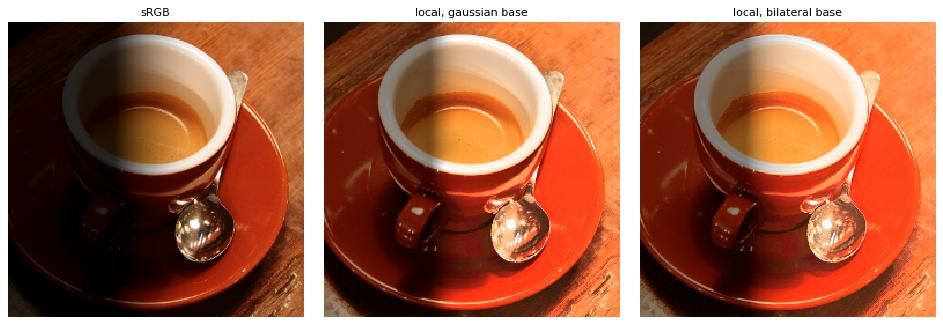

In [14]:
# Exercise 1: local tone mapping of another scene, with the bilateral base layer (edge-preserving, fewer halos)
hc2 = scenes.high_contrast(256, 'coffee')
show_row([tonemap.tonemap(hc2, 'srgb'), tonemap.tonemap(hc2, 'local', strength=0.8),
          tonemap.tonemap(hc2, 'local', strength=0.8, base='bilateral')],
         ['sRGB', 'local, gaussian base', 'local, bilateral base'], figsize=(12, 4))